In [1]:
from pathlib import Path
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
path = kagglehub.dataset_download("eouedraogo4/steel-plates-faults")

  0%|          | 0.00/103k [00:00<?, ?B/s]

100%|██████████| 103k/103k [00:00<00:00, 267kB/s]

100%|██████████| 103k/103k [00:00<00:00, 266kB/s]

Extracting files...


In [3]:
df = pd.read_csv(Path(path) / "SteelPlatesFaults.csv")
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empty_Index    

In [5]:
targets = df.iloc[:, -7:]
steel = df[["TypeOfSteel_A300", "TypeOfSteel_A400"]]
measurements = df[["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Length_of_Conveyer","Steel_Plate_Thickness"]]

checks = pd.Series({
    "Строки с пропусками": df.isna().any(axis=1).sum(),
    "Строки с бесконечностями": df.isin([float("inf"), -float("inf")]).any(axis=1).sum(),
    "Полные дубли": df.duplicated().sum(),
    "Повторы набора признаков": df.duplicated(subset=df.columns[:27]).sum(),
    "Неположительные размеры по координатам": ((df["X_Minimum"] >= df["X_Maximum"]) | (df["Y_Minimum"] >= df["Y_Maximum"])).sum(),
    "Неположительные измерения": measurements.le(0).any(axis=1).sum(),
    "Некорректные индикаторы стали": (~steel.isin([0, 1]).all(axis=1) | steel.sum(axis=1).ne(1)).sum(),
    "Некорректная разметка класса": (~targets.isin([0, 1]).all(axis=1) | targets.sum(axis=1).ne(1)).sum(),
    "Минимальная яркость выше максимальной": (df["Minimum_of_Luminosity"] > df["Maximum_of_Luminosity"]).sum(),
}, name="Количество строк")

checks.to_frame()

,Количество строк
Строки с пропусками,0
Строки с бесконечностями,0
Полные дубли,0
Повторы набора признаков,0
Неположительные размеры по координатам,0
Неположительные измерения,0
Некорректные индикаторы стали,0
Некорректная разметка класса,0
Минимальная яркость выше максимальной,0


In [7]:
target_columns = df.columns[-7:]

y = df[target_columns].idxmax(axis=1)
X = df.drop(columns=target_columns)

y.value_counts()

Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

In [8]:
y.value_counts(normalize=True).mul(100).round(2)

Other_Faults    34.67
Bumps           20.71
K_Scatch        20.14
Z_Scratch        9.79
Pastry           8.14
Stains           3.71
Dirtiness        2.83
Name: proportion, dtype: float64

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train.shape, X_test.shape

((1552, 27), (389, 27))

In [10]:
pd.DataFrame({
    "Обучающая": y_train.value_counts(),
    "Тестовая": y_test.value_counts()
})

,Обучающая,Тестовая
Other_Faults,538,135
Bumps,321,81
K_Scatch,313,78
Z_Scratch,152,38
Pastry,126,32
Stains,58,14
Dirtiness,44,11


## EDA

In [11]:
X_train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1552.0,562.051,515.218,0.000,52.750,405.500,1038.750,1.705000e+03
X_Maximum,1552.0,609.570,492.280,4.000,192.750,445.000,1061.500,1.713000e+03
Y_Minimum,1552.0,1662716.644,1811260.019,6712.000,462923.500,1188619.000,2182183.500,1.298766e+07
Y_Maximum,1552.0,1662761.350,1811258.419,6724.000,462947.250,1188705.500,2182200.250,1.298769e+07
Pixels_Areas,1552.0,1870.083,4007.856,2.000,85.000,170.500,822.500,3.733400e+04
X_Perimeter,1552.0,107.993,192.130,2.000,15.000,26.500,83.250,1.275000e+03
Y_Perimeter,1552.0,74.538,119.202,1.000,13.000,25.000,80.000,9.030000e+02
Sum_of_Luminosity,1552.0,206718.642,459112.724,250.000,9548.750,19125.000,83647.250,3.918209e+06
Minimum_of_Luminosity,1552.0,84.506,32.456,0.000,62.000,90.000,106.000,2.030000e+02
Maximum_of_Luminosity,1552.0,130.195,18.980,37.000,124.000,127.000,140.000,2.530000e+02


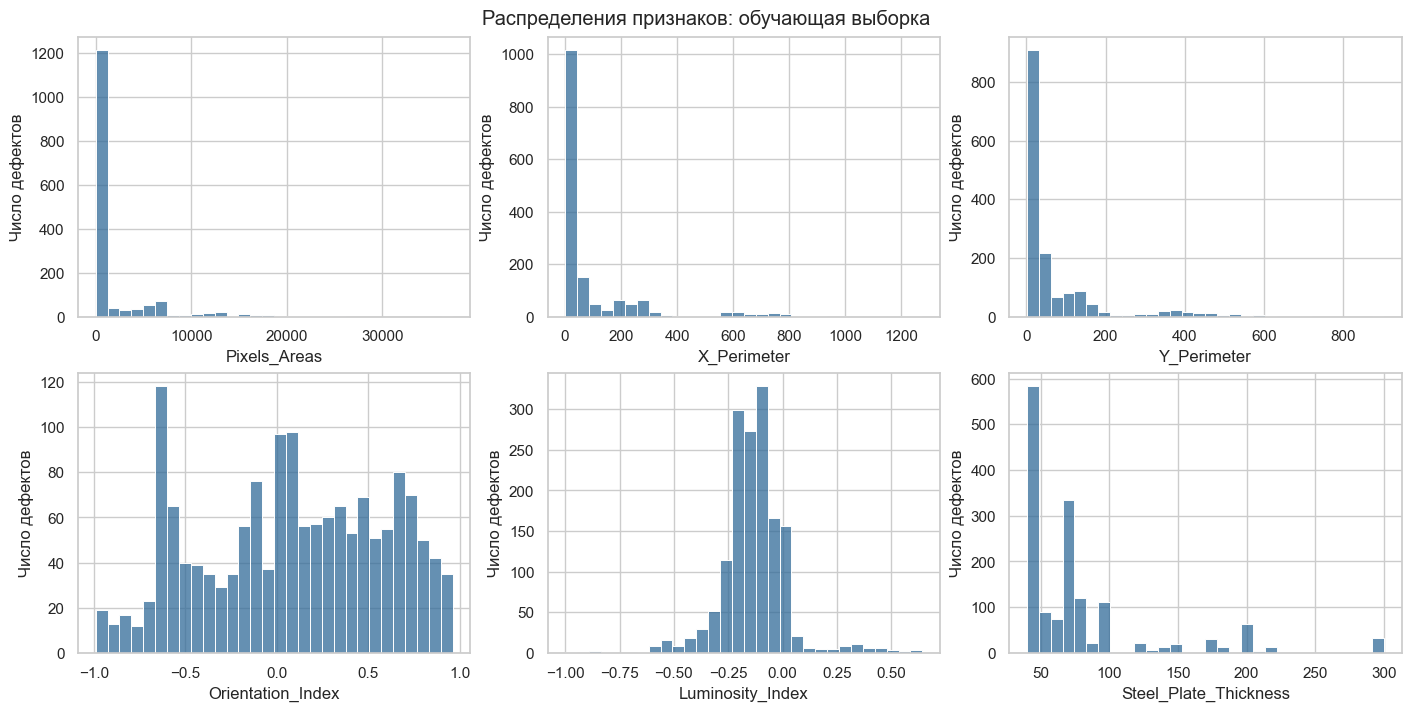

In [12]:
features = [
    "Pixels_Areas", "X_Perimeter", "Y_Perimeter",
    "Orientation_Index", "Luminosity_Index", "Steel_Plate_Thickness"
]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout="constrained")
for feature, ax in zip(features, axes.flat):
    sns.histplot(X_train[feature], bins=30, color="#326b98", ax=ax)
    ax.set(xlabel=feature, ylabel="Число дефектов")
fig.suptitle("Распределения признаков: обучающая выборка")
plt.show()

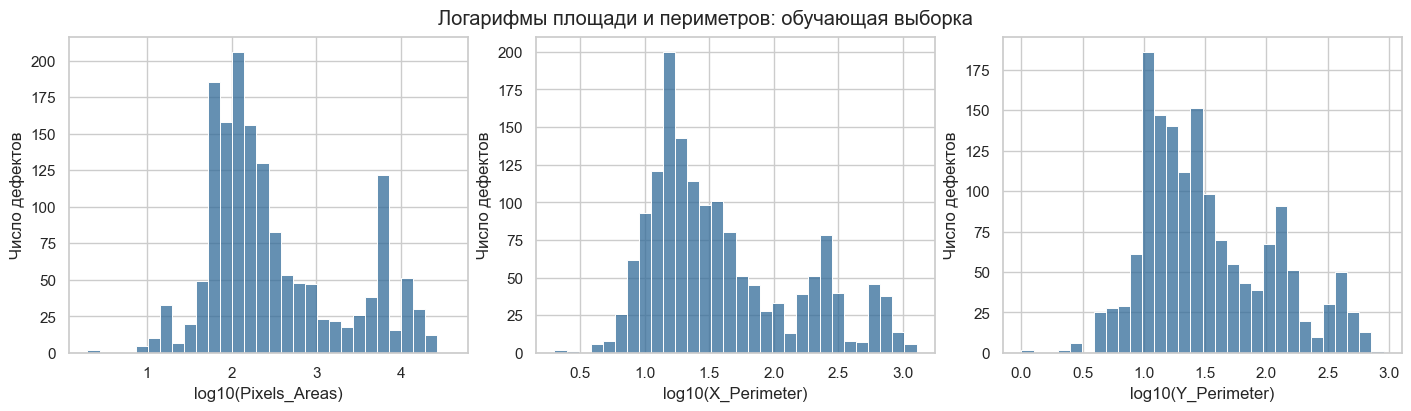

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for feature, ax in zip(features[:3], axes):
    sns.histplot(np.log10(X_train[feature]), bins=30, color="#326b98", ax=ax)
    ax.set(xlabel=f"log10({feature})", ylabel="Число дефектов")
fig.suptitle("Логарифмы площади и периметров: обучающая выборка")
plt.show()

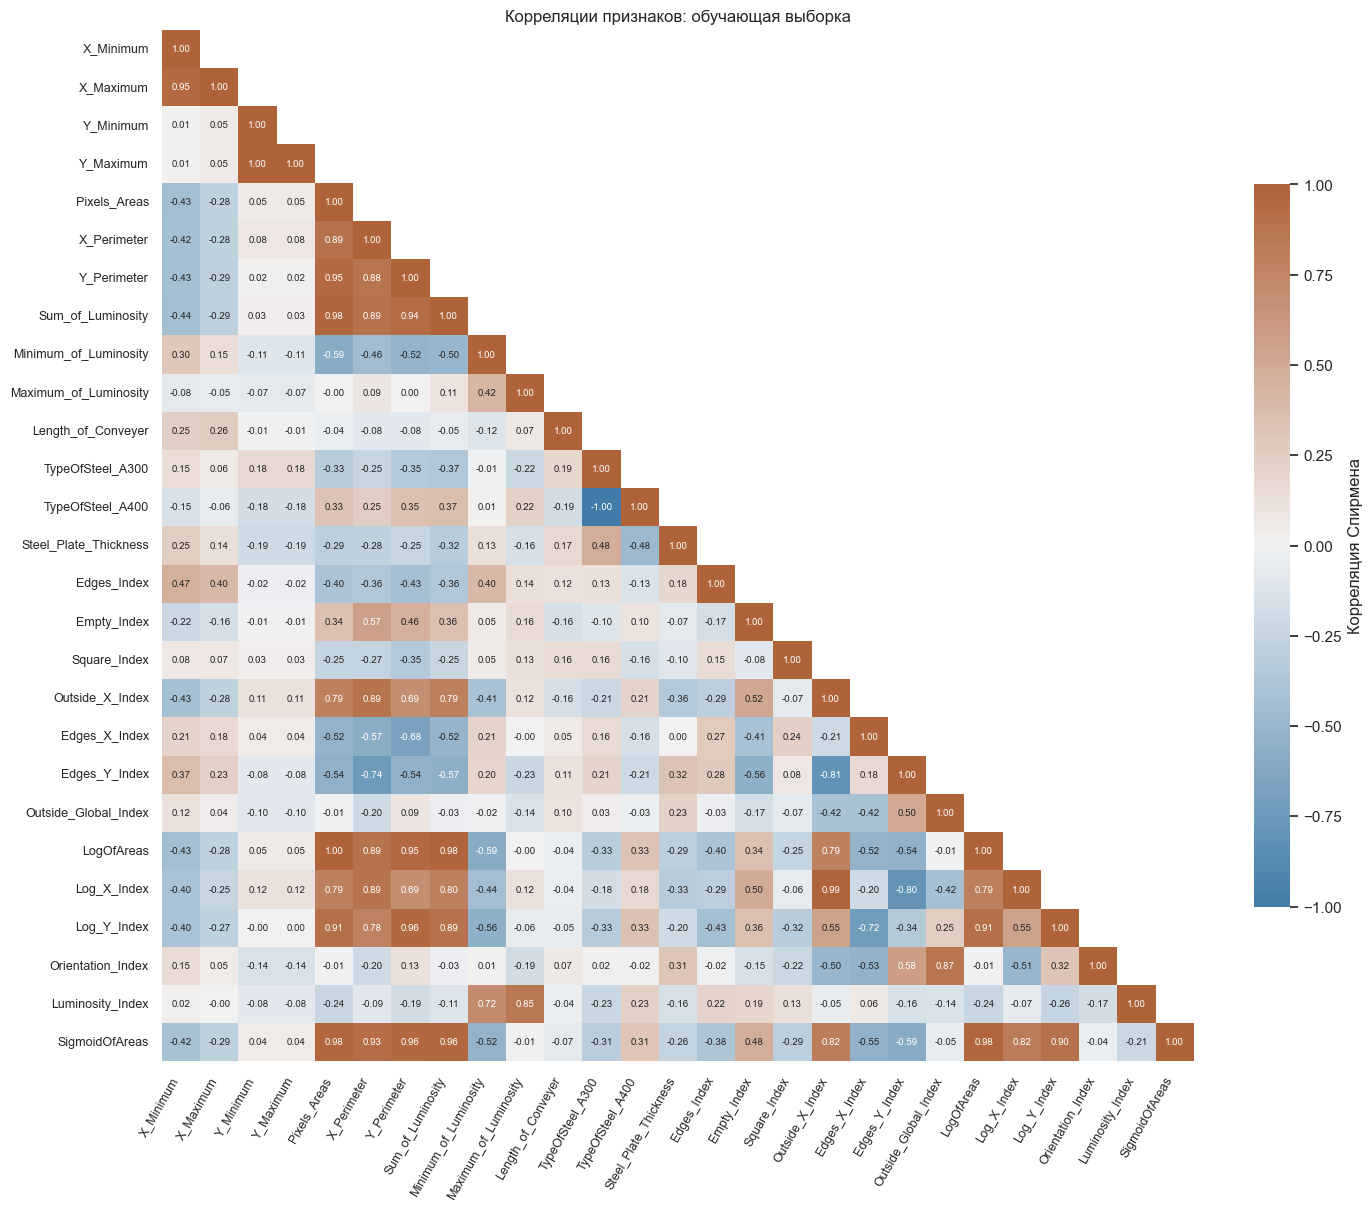

In [14]:
corr = X_train.corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12), layout="constrained")
sns.heatmap(
    corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
    cmap=sns.diverging_palette(240, 30, as_cmap=True),
    vmin=-1, vmax=1, center=0, square=True,
    cbar_kws={"label": "Корреляция Спирмена", "shrink": 0.7},
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    ax=ax
)
ax.grid(False)
ax.set_title("Корреляции признаков: обучающая выборка")
ax.tick_params(axis="both", labelsize=9)
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.show()

In [15]:
pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
strong_pairs = pairs[pairs.abs() > 0.9].sort_values(key=lambda x: x.abs(), ascending=False)
strong_pairs.rename_axis(["Признак 1", "Признак 2"]).reset_index(name="Спирмен").round(4)

,Признак 1,Признак 2,Спирмен
0,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000
1,Pixels_Areas,LogOfAreas,1.0000
2,Y_Minimum,Y_Maximum,1.0000
3,Outside_X_Index,Log_X_Index,0.9885
4,Pixels_Areas,Sum_of_Luminosity,0.9836
5,Sum_of_Luminosity,LogOfAreas,0.9836
6,LogOfAreas,SigmoidOfAreas,0.9760
7,Pixels_Areas,SigmoidOfAreas,0.9760
8,Sum_of_Luminosity,SigmoidOfAreas,0.9637
9,Y_Perimeter,SigmoidOfAreas,0.9562


In [16]:
eda = X_train.join(y_train.rename("Класс"))
class_order = y_train.value_counts().index
compare_features = ["Pixels_Areas", "Orientation_Index", "Luminosity_Index"]

eda.groupby("Класс").agg(
    Количество=("Pixels_Areas", "size"),
    Медиана_площади=("Pixels_Areas", "median"),
    Медиана_ориентации=("Orientation_Index", "median"),
    Медиана_яркости=("Luminosity_Index", "median")
).reindex(class_order).round(3)

,Количество,Медиана_площади,Медиана_ориентации,Медиана_яркости
Other_Faults,538,146.0,0.178,-0.120
Bumps,321,121.0,0.100,-0.143
K_Scatch,313,6298.0,-0.537,-0.156
Z_Scratch,152,152.0,0.365,-0.161
Pastry,126,210.5,0.667,-0.185
Stains,58,16.0,-0.250,-0.000
Dirtiness,44,130.5,0.781,-0.086


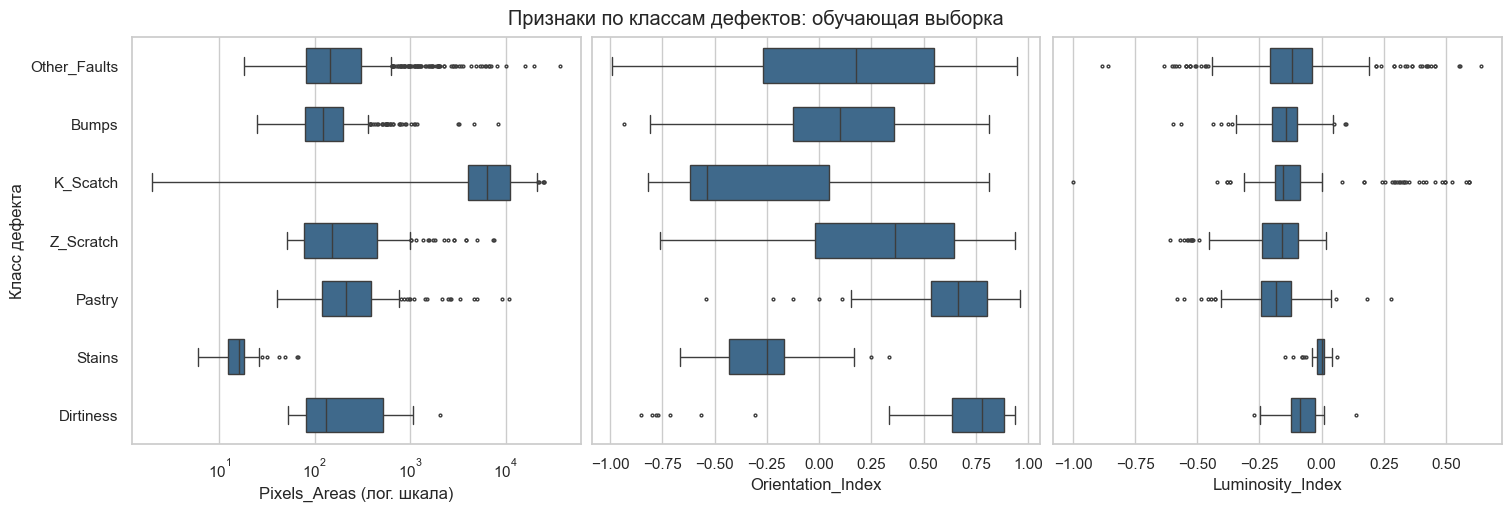

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, layout="constrained")
for feature, ax in zip(compare_features, axes):
    sns.boxplot(
        data=eda, x=feature, y="Класс", order=class_order,
        color="#326b98", width=0.6, linewidth=1,
        flierprops={"markersize": 2}, ax=ax
    )
    ax.set(xlabel=feature, ylabel="")
axes[0].set_xscale("log")
axes[0].set(xlabel="Pixels_Areas (лог. шкала)", ylabel="Класс дефекта")
fig.suptitle("Признаки по классам дефектов: обучающая выборка")
plt.show()

## Базовые модели

In [18]:
logreg = OneVsRestClassifier(
    LogisticRegression(solver="liblinear", max_iter=10000, tol=1e-6, random_state=42)
)

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "LogReg OvR": logreg,
    "LogReg OvR + StandardScaler": make_pipeline(StandardScaler(), logreg),
    "Tree depth=10": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Tree depth=None": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2)
}

In [19]:
cv_results = {}
rows = []

for name, model in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        scores = cross_validate(
            model, X_train, y_train, cv=cv,
            scoring={"f1": "f1_macro", "accuracy": "accuracy"},
            return_train_score=True, error_score="raise"
        )
    cv_results[name] = scores
    rows.append({
        "Модель": name,
        "F1 train": scores["train_f1"].mean(),
        "F1 CV": scores["test_f1"].mean(),
        "std F1 CV": scores["test_f1"].std(ddof=1),
        "accuracy CV": scores["test_accuracy"].mean()
    })

baseline_results = pd.DataFrame(rows).set_index("Модель").sort_values("F1 CV", ascending=False)
baseline_results.round(3)

,F1 train,F1 CV,std F1 CV,accuracy CV
Модель,,,,
Random Forest,1.000,0.792,0.025,0.778
Tree depth=10,0.905,0.731,0.022,0.729
Tree depth=None,1.000,0.726,0.025,0.712
LogReg OvR + StandardScaler,0.730,0.700,0.031,0.705
LogReg OvR,0.611,0.600,0.048,0.644
Dummy,0.074,0.074,0.000,0.347


## Подбор гиперпараметров

In [20]:
baseline_names = {
    "LogReg OvR + StandardScaler": "LogReg OvR + StandardScaler",
    "Decision Tree": "Tree depth=10",
    "Random Forest": "Random Forest"
}

param_grids = {
    "LogReg OvR + StandardScaler": {
        "onevsrestclassifier__estimator__C": [0.01, 0.1, 1, 10, 100],
        "onevsrestclassifier__estimator__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "max_depth": [3, 5, 10, 15, None],
        "min_samples_leaf": [1, 2, 5],
        "criterion": ["gini", "entropy"]
    },
    "Random Forest": {
        "max_depth": [10, None],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.5]
    }
}

In [21]:
searches = {}
tuning_rows = []

for name, param_grid in param_grids.items():
    search = GridSearchCV(
        models[baseline_names[name]], param_grid, cv=cv,
        scoring={"f1": "f1_macro", "accuracy": "accuracy"},
        refit="f1", return_train_score=True, error_score="raise"
    )
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        search.fit(X_train, y_train)
    searches[name] = search
    best = search.best_index_
    fold_f1 = [search.cv_results_[f"split{i}_test_f1"][best] for i in range(cv.n_splits)]
    before = baseline_results.loc[baseline_names[name], "F1 CV"]
    tuning_rows.append({
        "Модель": name,
        "F1 CV до": before,
        "F1 CV после": search.best_score_,
        "Δ F1 CV": search.best_score_ - before,
        "F1 train": search.cv_results_["mean_train_f1"][best],
        "std F1 CV": np.std(fold_f1, ddof=1),
        "accuracy CV": search.cv_results_["mean_test_accuracy"][best]
    })

tuning_results = pd.DataFrame(tuning_rows).set_index("Модель").sort_values("F1 CV после", ascending=False)
tuning_results.round(3)

,F1 CV до,F1 CV после,Δ F1 CV,F1 train,std F1 CV,accuracy CV
Модель,,,,,,
Random Forest,0.792,0.801,0.009,1.000,0.018,0.785
Decision Tree,0.731,0.753,0.023,0.923,0.023,0.736
LogReg OvR + StandardScaler,0.700,0.715,0.015,0.757,0.013,0.716


In [22]:
pd.DataFrame([
    (name, param.split("__")[-1], value)
    for name, search in searches.items()
    for param, value in search.best_params_.items()
], columns=["Модель", "Параметр", "Значение"])

,Модель,Параметр,Значение
0,LogReg OvR + StandardScaler,C,100
1,LogReg OvR + StandardScaler,class_weight,None
2,Decision Tree,criterion,entropy
3,Decision Tree,max_depth,10
4,Decision Tree,min_samples_leaf,2
5,Random Forest,max_depth,None
6,Random Forest,max_features,0.5
7,Random Forest,min_samples_leaf,1


## Отбор признаков

In [23]:
class CorrelationSelector(TransformerMixin, BaseEstimator):
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y=None):
        corr = X.corr(method="spearman").abs().fillna(0)
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = X.columns.to_numpy()
        self.columns_ = []
        for column in X.columns:
            if not self.columns_ or corr.loc[column, self.columns_].le(self.threshold).all():
                self.columns_.append(column)
        return self

    def transform(self, X):
        return X.loc[:, self.columns_]

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)

In [24]:
best_logreg = searches["LogReg OvR + StandardScaler"].best_estimator_
classifier = best_logreg.named_steps["onevsrestclassifier"]

selection_models = {
    "Все признаки": clone(best_logreg),
    "Корреляция > 0.9": make_pipeline(
        CorrelationSelector(), StandardScaler(), clone(classifier)
    ),
    "SelectKBest k=10": make_pipeline(
        SelectKBest(f_classif, k=10), StandardScaler(), clone(classifier)
    )
}

In [25]:
selection_cv_results = {}
selection_rows = []

for name, model in selection_models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        scores = cross_validate(
            model, X_train, y_train, cv=cv,
            scoring={"f1": "f1_macro", "accuracy": "accuracy"},
            return_estimator=True, error_score="raise"
        )
    selection_cv_results[name] = scores
    counts = [est.named_steps["onevsrestclassifier"].n_features_in_ for est in scores["estimator"]]
    selection_rows.append({
        "Вариант": name,
        "Признаков min": min(counts),
        "Признаков max": max(counts),
        "F1 CV": scores["test_f1"].mean(),
        "std F1 CV": scores["test_f1"].std(ddof=1),
        "accuracy CV": scores["test_accuracy"].mean()
    })

selection_results = pd.DataFrame(selection_rows).set_index("Вариант")
selection_results["Δ F1 CV"] = selection_results["F1 CV"] - selection_results.loc["Все признаки", "F1 CV"]
selection_results["Потеря ≤ 0.01"] = selection_results["Δ F1 CV"].ge(-0.01)
selection_results.round(3)

,Признаков min,Признаков max,F1 CV,std F1 CV,accuracy CV,Δ F1 CV,Потеря ≤ 0.01
Вариант,,,,,,,
Все признаки,27,27,0.715,0.013,0.716,0.000,True
Корреляция > 0.9,18,18,0.700,0.031,0.700,-0.015,False
SelectKBest k=10,10,10,0.525,0.035,0.598,-0.190,False


In [26]:
selection_frequency = pd.DataFrame({
    name: pd.Series(np.concatenate([
        est.steps[0][1].get_feature_names_out(X_train.columns)
        for est in scores["estimator"]
    ])).value_counts()
    for name, scores in selection_cv_results.items()
    if name != "Все признаки"
}).fillna(0).astype(int).sort_values("SelectKBest k=10", ascending=False)

selection_frequency.columns.name = f"Число отборов из {cv.n_splits}"
selection_frequency.rename_axis("Признак")

Число отборов из 5,Корреляция > 0.9,SelectKBest k=10
Признак,,
Edges_Y_Index,5,5
Log_Y_Index,0,5
Log_X_Index,0,5
LogOfAreas,0,5
Sum_of_Luminosity,0,5
X_Perimeter,5,5
Outside_X_Index,5,5
Pixels_Areas,5,5
TypeOfSteel_A300,5,4


## Выводы по гипотезам (CV)

| № | Итог | Результат |
|---|---|---|
| 1 | Подтвердилась | Масштабирование: F1 0.600 → 0.700. |
| 2 | Подтвердилась по качеству | Лес: 0.801; LogReg: 0.715. Причина преимущества не проверялась. |
| 3 | Частично | Train: 0.905 → 1.000; CV: 0.731 → 0.726, снижение в 4 из 5 блоков. |
| 4 | Не подтвердилась | 18 признаков: 0.715 → 0.700, потеря > 0.01. |
| 5 | Не подтвердилась | 10 признаков: 0.715 → 0.525. |
| 6 | Не подтвердилась | Accuracy − F1: 0.044 без / 0.005 с масштабированием (< 0.05). |

F1 — macro; статистическая значимость не проверялась.

## Итоговая оценка

In [27]:
best_name = tuning_results["F1 CV после"].idxmax()
final_model = searches[best_name].best_estimator_
y_pred = final_model.predict(X_test)

test_metrics = pd.Series({
    "F1-macro": f1_score(y_test, y_pred, average="macro"),
    "Accuracy": accuracy_score(y_test, y_pred)
}, name=best_name)
test_metrics.to_frame().round(3)

,Random Forest
F1-macro,0.803
Accuracy,0.797


In [28]:
labels = final_model.classes_
report = pd.DataFrame(classification_report(
    y_test, y_pred, labels=labels, output_dict=True, zero_division=0
)).T.drop(index="accuracy")
report["support"] = report["support"].astype(int)
report.round(3)

,precision,recall,f1-score,support
Bumps,0.731,0.704,0.717,81
Dirtiness,0.750,0.818,0.783,11
K_Scatch,0.972,0.897,0.933,78
Other_Faults,0.721,0.822,0.768,135
Pastry,0.654,0.531,0.586,32
Stains,0.923,0.857,0.889,14
Z_Scratch,1.000,0.895,0.944,38
macro avg,0.822,0.789,0.803,389
weighted avg,0.803,0.797,0.798,389


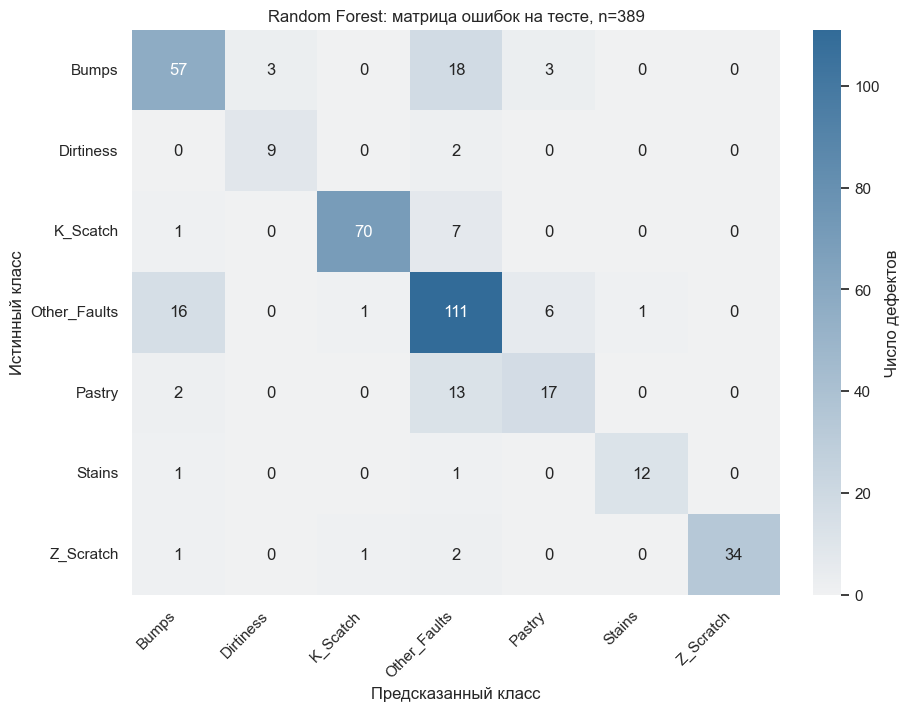

In [29]:
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
sns.heatmap(
    cm, annot=True, fmt="d", cmap=sns.light_palette("#326b98", as_cmap=True),
    vmin=0, xticklabels=labels, yticklabels=labels,
    cbar_kws={"label": "Число дефектов"}, ax=ax
)
ax.grid(False)
ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс",
       title=f"{best_name}: матрица ошибок на тесте, n={len(y_test)}")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.show()

`Pastry`: F1 = 0.586. `Bumps` ↔ `Other_Faults`: 34 ошибки.